# Redes bayesianas: estimación de parámetros e inferencia por enumeración

Implementación desde cero de una red bayesiana sobre el conjunto de datos
`data/weather.csv`. Se estiman las tablas de probabilidad condicional (CPT) por
frecuencias, se calcula la distribución conjunta mediante la regla del producto y se
resuelven consultas de inferencia — predictiva, diagnóstica e intercausal — con
enumeración exacta.

El modelado, la estimación y la inferencia son propios. `networkx` y `matplotlib` se
usan únicamente para dibujar la red y los gráficos, y `pandas` para la manipulación de
datos. Requisitos: Python 3.10 o superior, pandas, matplotlib y networkx.

## 1. Alcance y aplicabilidad

Una red bayesiana es un modelo probabilístico gráfico: un grafo dirigido acíclico (DAG)
cuyo nodo representa una variable aleatoria, cuyo arco representa una relación de
dependencia causal y donde cada nodo almacena su Tabla de Probabilidad Condicional
(CPT). La semántica del grafo es la de Markov: cada variable es condicionalmente
independiente de sus no-descendientes dado sus padres. Sobre esa estructura se puede
propagar evidencia observada y obtener distribuciones a posteriori de las variables
ocultas.

### Cuándo conviene usar redes bayesianas

- El dominio tiene múltiples causas para un mismo efecto y se necesita razonar en
  ambos sentidos: predictivo (causa a efecto) y diagnóstico (efecto a causa) sobre una
  misma estructura.
- Existe conocimiento causal defendible que fija la topología, y datos para estimar los
  parámetros. La estructura y los parámetros se aprenden por separado.
- La incertidumbre debe actualizarse de forma incremental a medida que llega evidencia
  (creencias a priori que se convierten en posteriores).
- Cada parámetro debe ser interpretable y auditable: una CPT se discute con un experto
  del dominio; un peso de red neuronal, no.
- El objetivo final es apoyar decisiones bajo incertidumbre; la red bayesiana es la
  base sobre la que se construyen las redes de decisión.

Casos donde la aproximación no es la adecuada:

- Sólo interesa predecir una variable objetivo y no interpretar el proceso: un modelo
  discriminativo rinde igual o mejor con menos supuestos.
- La estructura causal no es defendible y tampoco puede buscarse en los datos: el
  aprendizaje estructural es combinatorial y frágil con muestras chicas.
- Redes grandes: la inferencia exacta es exponencial en el peor caso, y sin
  topologías favorables (árboles, polígonos estrechos) hay que recurrir a métodos
  aproximados.
- Variables fundamentalmente continuas en alta dimensión: se necesitan variantes como
  redes gaussianas.

### Qué información entrega el modelo

Una red bayesiana parametrizada entrega distribuciones marginales y condicionales de
cualquier variable del dominio, condicionadas a la evidencia disponible; la cuantificación
del impacto de cada evidencia (diferencia entre prior y posterior); un modelo causal
interpretable donde cada actualización es trazable hasta sus parámetros; y una base
para análisis de sensibilidad y para toma de decisiones.

## 2. Marco teórico

### Variables, arcos y probabilidad conjunta

Cada nodo $X$ es una variable aleatoria con un conjunto de estados mutuamente
excluyentes y exhaustivos. Si existe un arco $X \to Y$, entonces $X$ es padre de $Y$ y
$Y$ depende probabilísticamente de $X$. La distribución conjunta de las variables del
dominio cumple:

$$\sum_{x, y, \ldots} P(X = x, Y = y, \ldots) = 1$$

### Regla del producto

La propiedad estructural de una red bayesiana es la factorización de la distribución
conjunta según las dependencias del grafo:

$$P(X_1, \ldots, X_n) = \prod_{i=1}^{n} P(X_i \mid \mathrm{Padres}(X_i))$$

En lugar de la tabla conjunta completa, cada variable aporta sólo su CPT. Un nodo sin
padres almacena probabilidades a priori; un nodo con padres almacena una distribución
por cada combinación de valores de sus padres.

### Teorema de Bayes y actualización de creencias

$$P(A \mid B) = \frac{P(B \mid A)\, P(A)}{P(B)}$$

$P(A)$ es la probabilidad a priori, antes de observar evidencia; $P(A \mid B)$ es la
probabilidad a posteriori, después de incorporar la evidencia $B$. La inferencia en la
red es esta actualización aplicada de forma sistemática a todas las variables.

### Inferencia por enumeración

La consulta típica es $P(Q \mid e)$ con $Q$ la variable consultada y $e$ la evidencia
observada. La enumeración exacta suma la probabilidad conjunta sobre todas las
asignaciones de las variables ocultas $w$ y normaliza:

$$P(q \mid e) = \frac{\sum_{w} P(q, w, e)}{\sum_{q' \in \mathrm{Estados}(Q)} \sum_{w} P(q', w, e)}$$

### Supuestos

1. La estructura del grafo está dada y es correcta; los arcos se leen como relaciones
   causales del dominio.
2. Las variables son discretas (booleanas en este caso) y no hay valores faltantes.
3. Las 50 instancias del dataset son independientes y representan a la distribución
   generadora.
4. Los parámetros se estiman por máxima verosimilitud (frecuencias relativas):
   aprendizaje paramétrico con estructura conocida.
5. Las filas de CPT sin observaciones se estiman con suavizado de Laplace
   ($\alpha = 1$) para mantener la normalización.
6. Un cero en una CPT se lee como imposibilidad observada en la muestra, no como ley
   física: las conclusiones sobre configuraciones nunca vistas dependen de este criterio.
7. La inferencia es exacta por enumeración; es viable aquí porque el dominio completo
   tiene $2^3$ configuraciones.

### Costo computacional

Con $n$ variables booleanas, la enumeración recorre $O(2^n)$ configuraciones. La
inferencia exacta en redes generales es NP-duro; en la práctica se usan eliminación de
variables, propagación de creencias en topologías de árbol o muestreo MCMC. Para este
dominio de tres variables, la enumeración directa es la opción más simple y verificable.

In [1]:
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

## 3. Conjunto de datos

`data/weather.csv` registra 50 días con tres variables booleanas. La topología de la
red que se modela es $Lluvia \to Aspersor$, $Lluvia \to Cesped\_Mojado$ y
$Aspersor \to Cesped\_Mojado$.

| Variable       | Estados   | Rol en la red                  |
|----------------|-----------|--------------------------------|
| Lluvia         | Si, No    | raíz, sin padres               |
| Aspersor       | Si, No    | hijo de Lluvia                 |
| Cesped_Mojado  | Si, No    | hijo de Lluvia y Aspersor      |

La muestra está desbalanceada: llueve en 10 de 50 días. La configuración
(Lluvia = Si, Aspersor = Si) no aparece en ningún registro, lo que tiene consecuencias
directas en la estimación de parámetros (sección 4).

In [2]:
RUTA = "data/weather.csv"

df = pd.read_csv(RUTA)
print(f"Instancias: {df.shape[0]}")
print(f"Variables : {list(df.columns)}")
for columna in df.columns:
    print(f"  {columna}: {dict(df[columna].value_counts())}")
df.head()

Instancias: 50
Variables : ['Lluvia', 'Aspersor', 'Cesped_Mojado']
  Lluvia: {'No': np.int64(40), 'Si': np.int64(10)}
  Aspersor: {'No': np.int64(27), 'Si': np.int64(23)}
  Cesped_Mojado: {'Si': np.int64(27), 'No': np.int64(23)}


,Lluvia,Aspersor,Cesped_Mojado
0,Si,No,Si
1,Si,No,Si
2,Si,No,Si
3,Si,No,Si
4,Si,No,Si


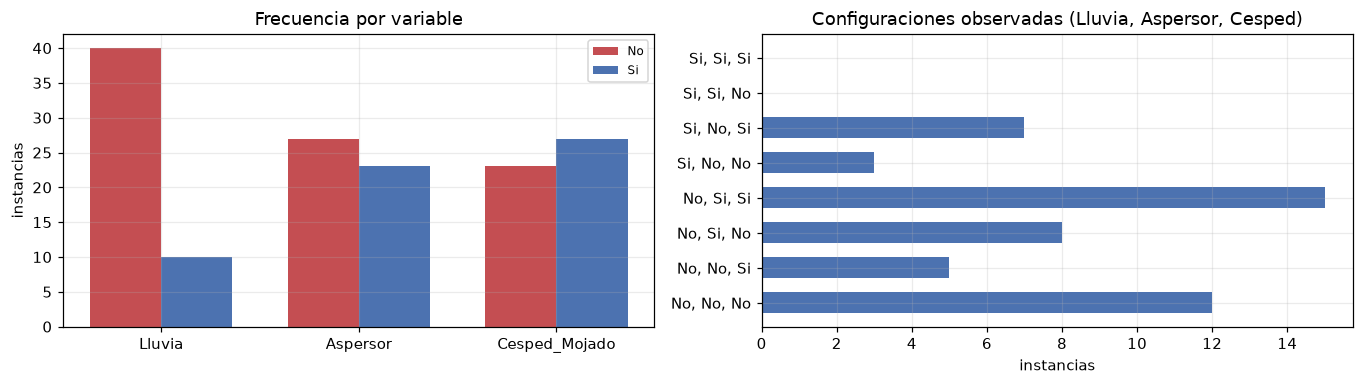

In [3]:
fig, ejes = plt.subplots(1, 2, figsize=(12.5, 3.6))

conteos = df.apply(lambda s: s.value_counts().reindex(["No", "Si"]))
x = np.arange(len(conteos.columns))
ejes[0].bar(x - 0.18, conteos.loc["No"], width=0.36, label="No", color="#c44e52")
ejes[0].bar(x + 0.18, conteos.loc["Si"], width=0.36, label="Si", color="#4c72b0")
ejes[0].set_xticks(x, conteos.columns)
ejes[0].set_ylabel("instancias")
ejes[0].set_title("Frecuencia por variable")
ejes[0].legend(fontsize=8)

configs = list(itertools.product(["No", "Si"], repeat=3))
etiquetas = [f"{l}, {a}, {c}" for l, a, c in configs]
frecuencias = [int(((df["Lluvia"] == l) & (df["Aspersor"] == a)
                    & (df["Cesped_Mojado"] == c)).sum()) for l, a, c in configs]
ejes[1].barh(etiquetas, frecuencias, color="#4c72b0", height=0.6)
ejes[1].set_xlabel("instancias")
ejes[1].set_title("Configuraciones observadas (Lluvia, Aspersor, Cesped)")

fig.tight_layout()
plt.show()

## 4. Aprendizaje paramétrico

Con la estructura fijada, el aprendizaje consiste en estimar cada CPT. Se usan
frecuencias relativas, equivalente a máxima verosimilitud:

$$P(X = x \mid \mathrm{Padres} = pa) = \frac{N(x, pa)}{N(pa)}$$

Cuando una configuración de padres no tiene observaciones, el cociente es 0/0. Aquí
esto ocurre en (Lluvia = Si, Aspersor = Si): el aspersor nunca se enciende con lluvia
en los 50 registros. Las filas sin observaciones se estiman con suavizado de Laplace
($\alpha = 1$):

$$P(x \mid pa) = \frac{N(x, pa) + 1}{N(pa) + |X|}$$

El valor asignado a esa fila no modifica la inferencia de esta red — la configuración
tiene probabilidad cero por la CPT del aspersor — pero deja todas las filas normalizadas
y el modelo consistente.

In [4]:
def estimar_cpt(df, variable, padres, estados, alfa=1):
    """Estima una CPT por frecuencias (MLE). Filas sin observaciones usan Laplace(alfa)."""
    valores_padres = [sorted(df[p].unique()) for p in padres]
    cpt, conteos = {}, {}
    for combinacion in itertools.product(*valores_padres):
        mascara = pd.Series(True, index=df.index)
        for padre, valor in zip(padres, combinacion):
            mascara &= df[padre] == valor
        sub = df[mascara]
        conteos[combinacion] = len(sub)
        if len(sub) == 0:
            cpt[combinacion] = {e: 1.0 / len(estados) for e in estados}
        else:
            frec = sub[variable].value_counts()
            cpt[combinacion] = {e: frec.get(e, 0) / len(sub) for e in estados}
    return cpt, conteos


ESPECIFICACION = [
    ("Lluvia", []),
    ("Aspersor", ["Lluvia"]),
    ("Cesped_Mojado", ["Lluvia", "Aspersor"]),
]

RED = {}
for variable, padres in ESPECIFICACION:
    cpt, conteos = estimar_cpt(df, variable, padres, sorted(df[variable].unique()))
    RED[variable] = {"padres": padres, "estados": sorted(df[variable].unique()),
                     "cpt": cpt, "conteos": conteos}


def cpt_a_dataframe(red, variable):
    """Presenta la CPT de una variable como tabla, con los conteos muestrales."""
    spec = red[variable]
    if not spec["padres"]:
        filas = [{"combinacion": "(prior)", "n": sum(spec["conteos"].values()), **spec["cpt"][()]}]
    else:
        filas = [{"combinacion": ", ".join(f"{p}={v}" for p, v in zip(spec["padres"], combo)),
                  "n": spec["conteos"][combo], **dist}
                 for combo, dist in spec["cpt"].items()]
    return pd.DataFrame(filas).set_index("combinacion")


for variable, _ in ESPECIFICACION:
    print(f"CPT de {variable} | padres: {RED[variable]['padres'] or 'ninguno'}")
    display(cpt_a_dataframe(RED, variable))
    print()

CPT de Lluvia | padres: ninguno


,n,No,Si
combinacion,,,
(prior),50,0.8,0.2



CPT de Aspersor | padres: ['Lluvia']


,n,No,Si
combinacion,,,
Lluvia=No,40,0.425,0.575
Lluvia=Si,10,1.000,0.000



CPT de Cesped_Mojado | padres: ['Lluvia', 'Aspersor']


,n,No,Si
combinacion,,,
"Lluvia=No, Aspersor=No",17,0.705882,0.294118
"Lluvia=No, Aspersor=Si",23,0.347826,0.652174
"Lluvia=Si, Aspersor=No",10,0.300000,0.700000
"Lluvia=Si, Aspersor=Si",0,0.500000,0.500000


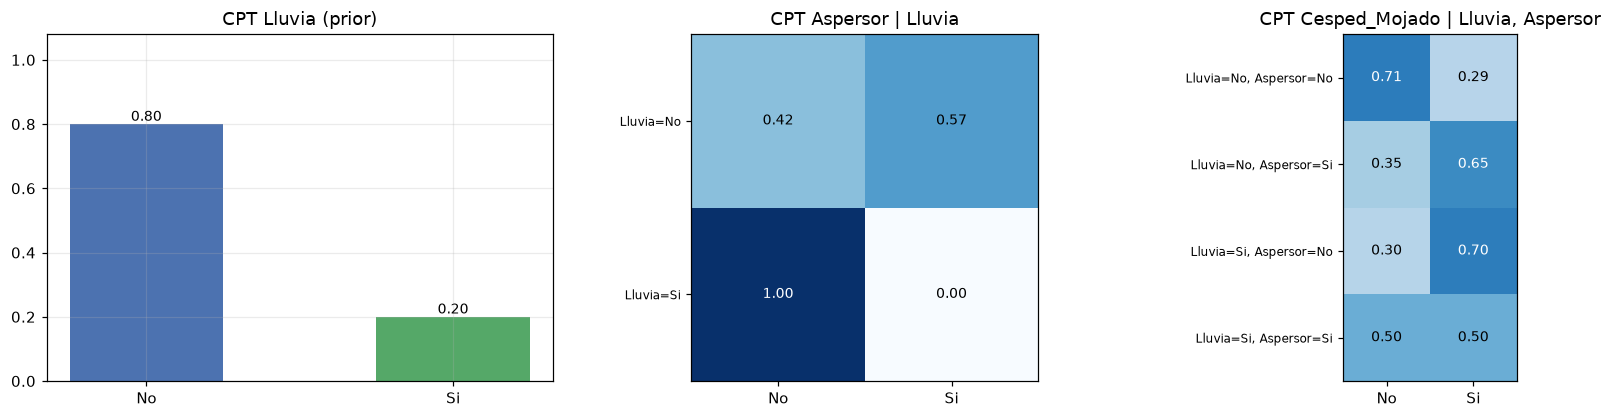

In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(15.5, 3.9))

estados = RED["Lluvia"]["estados"]
dist_raiz = RED["Lluvia"]["cpt"][()]
barras = ejes[0].bar(estados, [dist_raiz[e] for e in estados],
                     color=["#4c72b0", "#55a868"], width=0.5)
ejes[0].bar_label(barras, fmt="%.2f", fontsize=9)
ejes[0].set_ylim(0, 1.08)
ejes[0].set_title("CPT Lluvia (prior)")

def heatmap_cpt(ax, red, variable, titulo):
    spec = red[variable]
    filas = list(itertools.product(*[sorted(df[p].unique()) for p in spec["padres"]]))
    datos = np.array([[spec["cpt"][f][e] for e in spec["estados"]] for f in filas])
    ax.imshow(datos, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(spec["estados"])), spec["estados"])
    ax.set_yticks(range(len(filas)),
                  [", ".join(f"{p}={v}" for p, v in zip(spec["padres"], f)) for f in filas],
                  fontsize=8)
    for i in range(datos.shape[0]):
        for j in range(datos.shape[1]):
            ax.text(j, i, f"{datos[i, j]:.2f}", ha="center", va="center",
                    color="black" if datos[i, j] < 0.6 else "white", fontsize=9)
    ax.set_title(titulo)
    ax.grid(False)

heatmap_cpt(ejes[1], RED, "Aspersor", "CPT Aspersor | Lluvia")
heatmap_cpt(ejes[2], RED, "Cesped_Mojado", "CPT Cesped_Mojado | Lluvia, Aspersor")

fig.tight_layout()
plt.show()

## 5. Estructura de la red

La topología codifica el conocimiento causal del dominio: el programador del aspersor
reacciona al clima, la lluvia moja el césped directamente y el aspersor lo moja por su
cuenta. Con esa estructura, la regla del producto queda:

$$P(L, A, C) = P(L)\; P(A \mid L)\; P(C \mid L, A)$$

La figura dibuja el DAG. Los nodos raíz (sin padres) se distinguen de los hijos, y
cada nodo indica su conjunto de estados.

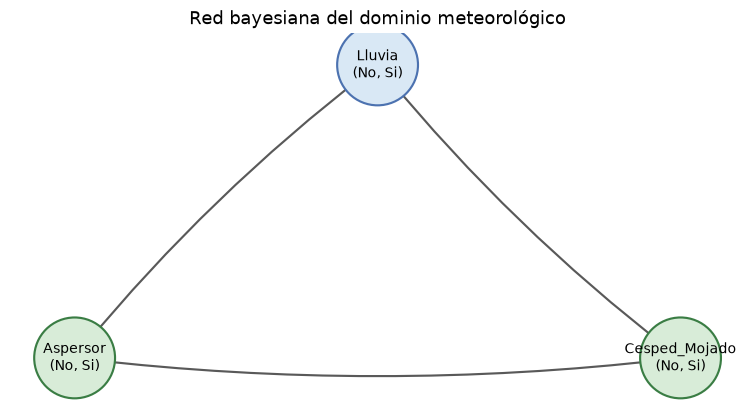

In [6]:
def dibujar_red(red, titulo=""):
    """Dibuja el DAG de la red con networkx: raices y hijos diferenciados, flujo causal."""
    grafo = nx.DiGraph()
    for variable, spec in red.items():
        grafo.add_node(variable)
        for padre in spec["padres"]:
            grafo.add_edge(padre, variable)

    posiciones = {"Lluvia": (0, 1), "Aspersor": (-0.9, 0), "Cesped_Mojado": (0.9, 0)}
    raices = [n for n in grafo if grafo.in_degree(n) == 0]

    fig, ax = plt.subplots(figsize=(8.6, 4.4))
    ax.axis("off")
    nx.draw_networkx_edges(grafo, posiciones, ax=ax, arrows=True, arrowstyle="-|>",
                           arrowsize=18, width=1.4, edge_color="0.35",
                           connectionstyle="arc3,rad=0.06")
    nx.draw_networkx_nodes(grafo, posiciones, ax=ax, node_size=2800,
                           node_color=["#d9e8f5" if n in raices else "#d8ecd8" for n in grafo],
                           edgecolors=["#4c72b0" if n in raices else "#3a7d44" for n in grafo],
                           linewidths=1.4)
    etiquetas = {n: f"{n}\n({', '.join(red[n]['estados'])})" for n in grafo}
    nx.draw_networkx_labels(grafo, posiciones, etiquetas, ax=ax, font_size=9)
    if titulo:
        ax.set_title(titulo)
    plt.show()


dibujar_red(RED, titulo="Red bayesiana del dominio meteorológico")

In [7]:
def probabilidad_conjunta(red, asignacion):
    """P(asignacion completa) por la regla del producto sobre las CPT."""
    p = 1.0
    for variable, spec in red.items():
        clave = tuple(asignacion[padre] for padre in spec["padres"])
        p *= spec["cpt"][clave][asignacion[variable]]
    return p


combinaciones = list(itertools.product(*[RED[v]["estados"] for v in RED]))
tabla_conjunta = pd.DataFrame(
    [{"Lluvia": l, "Aspersor": a, "Cesped_Mojado": c,
      "P": probabilidad_conjunta(RED, {"Lluvia": l, "Aspersor": a, "Cesped_Mojado": c})}
     for l, a, c in combinaciones])

print(f"Suma de la distribucion conjunta: {tabla_conjunta['P'].sum():.6f}")
tabla_conjunta.assign(P=tabla_conjunta["P"].round(4))

Suma de la distribucion conjunta: 1.000000


,Lluvia,Aspersor,Cesped_Mojado,P
0,No,No,No,0.24
1,No,No,Si,0.10
2,No,Si,No,0.16
3,No,Si,Si,0.30
4,Si,No,No,0.06
5,Si,No,Si,0.14
6,Si,Si,No,0.00
7,Si,Si,Si,0.00


## 6. Inferencia por enumeración

Pseudocódigo de la consulta $P(Q \mid e)$:

```text
inferencia(Q, evidencia e):
    para cada estado x de Q:
        num[x] <- enumerar(Q = x, e)    # suma P(q, w, e) sobre las variables ocultas w
    Z <- suma de los num[x]
    devolver num / Z                     # normalizacion
```

`enumerar` recorre recursivamente las variables sin asignar y consulta
`probabilidad_conjunta` cuando la asignación está completa. Con tres variables el
dominio de enumeración tiene ocho configuraciones; el algoritmo no depende de ese
tamaño y escala con la complejidad de la sección 2.

In [8]:
def enumerar(red, asignacion):
    """Suma la probabilidad conjunta sobre las variables todavia sin asignar."""
    pendientes = [v for v in red if v not in asignacion]
    if not pendientes:
        return probabilidad_conjunta(red, asignacion)
    variable = pendientes[0]
    return sum(enumerar(red, {**asignacion, variable: e}) for e in red[variable]["estados"])


def inferencia(red, consulta, evidencia=None):
    """P(consulta | evidencia) por enumeracion exacta y normalizacion."""
    evidencia = evidencia or {}
    numeradores = {e: enumerar(red, {**evidencia, consulta: e})
                   for e in red[consulta]["estados"]}
    total = sum(numeradores.values())
    return {e: numeradores[e] / total for e in red[consulta]["estados"]}


def mostrar(consulta, etiqueta, evidencia=None):
    dist = inferencia(RED, consulta, evidencia)
    texto = ", ".join(f"{e}: {p:.4f}" for e, p in dist.items())
    print(f"P({consulta} | {etiqueta}) = {{ {texto} }}")


mostrar("Lluvia", "sin evidencia")
mostrar("Lluvia", "Cesped_Mojado = Si", {"Cesped_Mojado": "Si"})
mostrar("Lluvia", "Cesped_Mojado = No", {"Cesped_Mojado": "No"})
mostrar("Lluvia", "Cesped_Mojado = Si, Aspersor = No", {"Cesped_Mojado": "Si", "Aspersor": "No"})
mostrar("Lluvia", "Cesped_Mojado = Si, Aspersor = Si", {"Cesped_Mojado": "Si", "Aspersor": "Si"})
mostrar("Cesped_Mojado", "Lluvia = Si", {"Lluvia": "Si"})
mostrar("Cesped_Mojado", "Lluvia = No", {"Lluvia": "No"})

P(Lluvia | sin evidencia) = { No: 0.8000, Si: 0.2000 }
P(Lluvia | Cesped_Mojado = Si) = { No: 0.7407, Si: 0.2593 }
P(Lluvia | Cesped_Mojado = No) = { No: 0.8696, Si: 0.1304 }
P(Lluvia | Cesped_Mojado = Si, Aspersor = No) = { No: 0.4167, Si: 0.5833 }
P(Lluvia | Cesped_Mojado = Si, Aspersor = Si) = { No: 1.0000, Si: 0.0000 }
P(Cesped_Mojado | Lluvia = Si) = { No: 0.3000, Si: 0.7000 }
P(Cesped_Mojado | Lluvia = No) = { No: 0.5000, Si: 0.5000 }


## 7. Análisis del impacto de la evidencia

La inferencia anterior permite comparar el prior de Lluvia con los posteriores bajo
distinta evidencia, y observar el efecto intercausal entre las dos causas del césped
mojado (*explaining away*): ambas causas explican el mismo efecto, así que conocer el
estado de una modifica el peso de la otra.

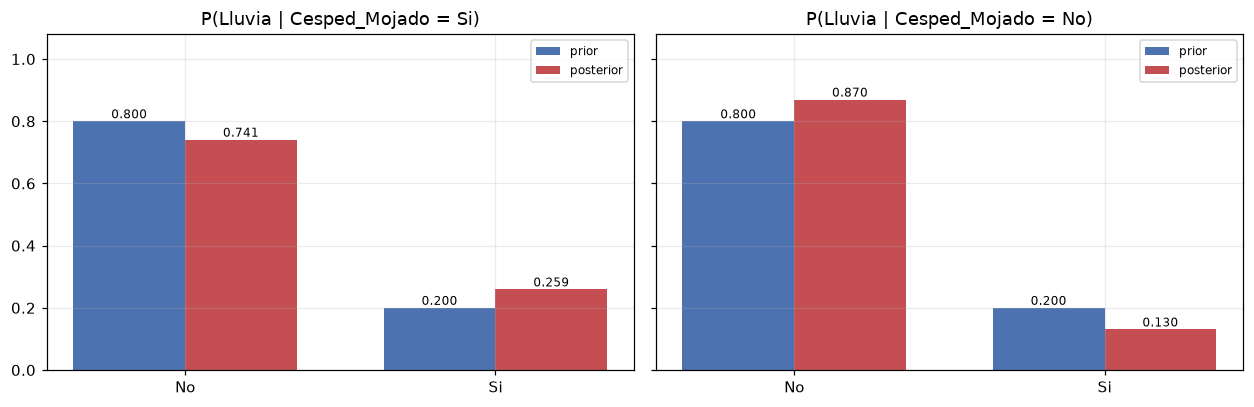

,No,Si,delta Si
evidencia,,,
sin evidencia,0.8000,0.2000,0.0000
Cesped_Mojado = Si,0.7407,0.2593,0.0593
Cesped_Mojado = No,0.8696,0.1304,-0.0696
"Cesped_Mojado = Si, Aspersor = No",0.4167,0.5833,0.3833
"Cesped_Mojado = Si, Aspersor = Si",1.0000,0.0000,-0.2000


In [9]:
prior = inferencia(RED, "Lluvia")
posterior_si = inferencia(RED, "Lluvia", {"Cesped_Mojado": "Si"})
posterior_no = inferencia(RED, "Lluvia", {"Cesped_Mojado": "No"})

fig, ejes = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
for ax, (titulo, dist) in zip(ejes, [("Cesped_Mojado = Si", posterior_si),
                                     ("Cesped_Mojado = No", posterior_no)]):
    x = np.arange(len(estados))
    barras_prior = ax.bar(x - 0.18, [prior[e] for e in estados], width=0.36,
                          label="prior", color="#4c72b0")
    barras_post = ax.bar(x + 0.18, [dist[e] for e in estados], width=0.36,
                         label="posterior", color="#c44e52")
    ax.bar_label(barras_prior, fmt="%.3f", fontsize=8)
    ax.bar_label(barras_post, fmt="%.3f", fontsize=8)
    ax.set_xticks(x, estados)
    ax.set_ylim(0, 1.08)
    ax.set_title(f"P(Lluvia | {titulo})")
    ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

impacto = pd.DataFrame([
    {"evidencia": "sin evidencia", **prior},
    {"evidencia": "Cesped_Mojado = Si", **posterior_si},
    {"evidencia": "Cesped_Mojado = No", **posterior_no},
    {"evidencia": "Cesped_Mojado = Si, Aspersor = No",
     **inferencia(RED, "Lluvia", {"Cesped_Mojado": "Si", "Aspersor": "No"})},
    {"evidencia": "Cesped_Mojado = Si, Aspersor = Si",
     **inferencia(RED, "Lluvia", {"Cesped_Mojado": "Si", "Aspersor": "Si"})},
]).set_index("evidencia")
impacto["delta Si"] = impacto["Si"] - prior["Si"]
impacto.round(4)

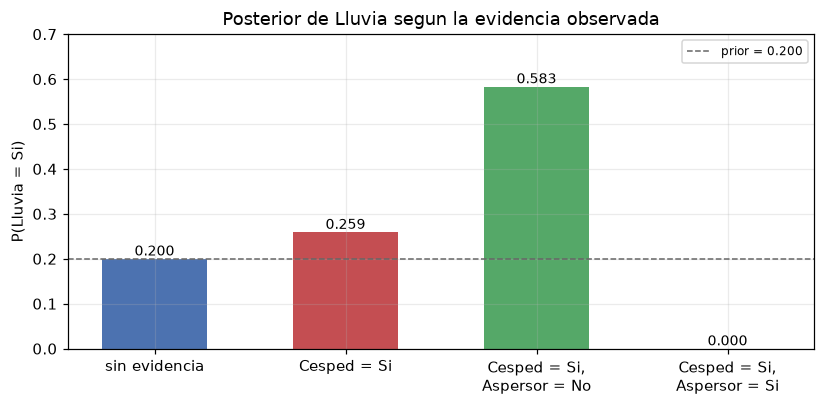

In [10]:
escenarios = [
    ("sin evidencia", {}),
    ("Cesped = Si", {"Cesped_Mojado": "Si"}),
    ("Cesped = Si,\nAspersor = No", {"Cesped_Mojado": "Si", "Aspersor": "No"}),
    ("Cesped = Si,\nAspersor = Si", {"Cesped_Mojado": "Si", "Aspersor": "Si"}),
]
valores = [inferencia(RED, "Lluvia", ev).get("Si", 0.0) for _, ev in escenarios]

fig, ax = plt.subplots(figsize=(7.6, 3.8))
barras = ax.bar([n for n, _ in escenarios], valores, width=0.55,
                color=["#4c72b0", "#c44e52", "#55a868", "#8172b3"])
ax.axhline(prior["Si"], color="0.4", ls="--", lw=1, label=f"prior = {prior['Si']:.3f}")
ax.bar_label(barras, fmt="%.3f", fontsize=9)
ax.set_ylabel("P(Lluvia = Si)")
ax.set_ylim(0, 0.70)
ax.set_title("Posterior de Lluvia segun la evidencia observada")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 8. Validación del modelo contra las frecuencias

Con parámetros estimados por máxima verosimilitud y datos completos, las marginales del
modelo deben coincidir con las frecuencias empíricas. La celda compara ambas para las
tres variables; la última columna es la máxima diferencia absoluta, que debe ser cero.
Sirve como verificación de la inferencia: si la enumeración o las CPT se rompen, la
coincidencia desaparece.

In [11]:
filas = []
for variable in RED:
    modelo = inferencia(RED, variable)
    frecuencia = df[variable].value_counts(normalize=True).to_dict()
    filas.append({
        "variable": variable,
        **{f"modelo {e}": modelo[e] for e in RED[variable]["estados"]},
        **{f"frecuencia {e}": frecuencia[e] for e in RED[variable]["estados"]},
        "max dif": max(abs(modelo[e] - frecuencia[e]) for e in RED[variable]["estados"]),
    })

pd.DataFrame(filas).set_index("variable").round(4)

,modelo No,modelo Si,frecuencia No,frecuencia Si,max dif
variable,,,,,
Lluvia,0.80,0.20,0.80,0.20,0.0
Aspersor,0.54,0.46,0.54,0.46,0.0
Cesped_Mojado,0.46,0.54,0.46,0.54,0.0


## 9. Conclusiones

- La red estima 7 parámetros libres (1 + 2 + 4, una fila independiente por CPT), el
  mismo número que exigiría la tabla conjunta: el grafo conecta las tres parejas de
  variables, así que en este caso la factorización no reduce parámetros. El valor de la
  representación es de modularidad y semántica — cada CPT se estima, revisa y actualiza
  por separado — y operativo: la inferencia propagada evita recalcular la distribución
  conjunta a mano para cada consulta. La reducción real aparece en estructuras más
  esparcidas, donde cada nodo depende de pocos padres.
- Con el césped mojado como evidencia, P(Lluvia = Si) pasa de 0.2000 a 0.2593. La
  evidencia es positiva pero débil: el efecto tiene dos causas y el aspersor se activa
  el 57.5 % de los días sin lluvia, lo que diluye la señal de la lluvia.
- El césped seco es evidencia negativa más marcada: baja el posterior a 0.1304.
- Condicionar Aspersor = No eleva el posterior a 0.5833 (efecto *explaining away*);
  condicionar Aspersor = Si lo lleva a exactamente cero por la regla determinista
  P(Aspersor = Si | Lluvia = Si) = 0 observada en las 10 instancias de lluvia. Ese cero
  es conocimiento de la muestra, no física del dominio: un suavizado de Laplace en esa
  celda la dejaría en 0.0833 y el posterior dejaría de ser nulo.
- La enumeración exacta es directa y verificable con $2^3$ configuraciones. En redes
  grandes el costo exponencial obliga a eliminación de variables, propagación de
  creencias sobre árboles o muestreo MCMC.

Extensiones naturales: análisis de sensibilidad de las CPT (qué parámetros dominan el
posterior), aprendizaje estructural con criterios tipo BIC sobre la misma base de datos,
y red de decisión para el problema operativo de cuándo conviene activar el aspersor.